# Steam Games Analytics

**Цель проекта:** проанализировать данные об играх Steam, чтобы понять, какие характеристики связаны с популярностью игр, их стоимостью и пользовательскими оценками.

**Бизнес-контекст:** игровая студия планирует выпустить новую игру и хочет лучше разобраться в особенностях рынка Steam.

### Бизнес-вопросы

В ходе анализа постараемся ответить на пять вопросов:

1. Какие жанры игр наиболее популярны?
2. Как цена игры связана с её популярностью и пользовательскими оценками?
3. Какие игры получают наиболее положительные оценки пользователей?
4. Как изменялось количество выпускаемых игр в Steam с течением времени?
5. Какие характеристики отличают самые популярные игры?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Data Understanding

На первом этапе познакомимся с датасетом: посмотрим на первые строки, размер таблицы, типы данных и описательную статистику. Также проверим наличие пропущенных значений и дубликатов.

In [2]:
steam_raw = pd.read_csv('data/steam.csv')
steam = steam_raw.copy()

In [3]:
steam_raw.head()

,appid,name,release_date,english,developer,publisher,platforms,required_age,categories,genres,steamspy_tags,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,owners,price
0,10,Counter-Strike,2000-11-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,124534,3339,17612,317,10000000-20000000,7.19
1,20,Team Fortress Classic,1999-04-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,3318,633,277,62,5000000-10000000,3.99
2,30,Day of Defeat,2003-05-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Valve Anti-Cheat enabled,Action,FPS;World War II;Multiplayer,0,3416,398,187,34,5000000-10000000,3.99
3,40,Deathmatch Classic,2001-06-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,1273,267,258,184,5000000-10000000,3.99
4,50,Half-Life: Opposing Force,1999-11-01,1,Gearbox Software,Valve,windows;mac;linux,0,Single-player;Multi-player;Valve Anti-Cheat en...,Action,FPS;Action;Sci-fi,0,5250,288,624,415,5000000-10000000,3.99


In [4]:
steam.shape

(27075, 18)

### Описательная статистика

Посмотрим на средние значения, медианы, квартили, а также минимальные и максимальные значения числовых признаков.

In [5]:
steam.describe()

,appid,english,required_age,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,price
count,2.707500e+04,27075.000000,27075.000000,27075.000000,2.707500e+04,27075.000000,27075.000000,27075.00000,27075.000000
mean,5.962035e+05,0.981127,0.354903,45.248864,1.000559e+03,211.027147,149.804949,146.05603,6.078193
std,2.508942e+05,0.136081,2.406044,352.670281,1.898872e+04,4284.938531,1827.038141,2353.88008,7.874922
min,1.000000e+01,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.00000,0.000000
25%,4.012300e+05,1.000000,0.000000,0.000000,6.000000e+00,2.000000,0.000000,0.00000,1.690000
50%,5.990700e+05,1.000000,0.000000,7.000000,2.400000e+01,9.000000,0.000000,0.00000,3.990000
75%,7.987600e+05,1.000000,0.000000,23.000000,1.260000e+02,42.000000,0.000000,0.00000,7.190000
max,1.069460e+06,1.000000,18.000000,9821.000000,2.644404e+06,487076.000000,190625.000000,190625.00000,421.990000


In [6]:
steam.dtypes

appid                 int64
name                    str
release_date            str
english               int64
developer               str
publisher               str
platforms               str
required_age          int64
categories              str
genres                  str
steamspy_tags           str
achievements          int64
positive_ratings      int64
negative_ratings      int64
average_playtime      int64
median_playtime       int64
owners                  str
price               float64
dtype: object

### Проверка пропущенных значений

Проверим количество пропущенных значений в каждом столбце. Пропуски обнаружены только в `developer` и `publisher`.

In [7]:
steam.isna().sum()

appid                0
name                 0
release_date         0
english              0
developer            1
publisher           14
platforms            0
required_age         0
categories           0
genres               0
steamspy_tags        0
achievements         0
positive_ratings     0
negative_ratings     0
average_playtime     0
median_playtime      0
owners               0
price                0
dtype: int64

### Проверка дубликатов

Проверим наличие полностью повторяющихся строк, а также дубликатов по `appid` и `name`.

Полных дубликатов и повторяющихся `appid` нет. Повторения обнаружены только в столбце `name`.

In [8]:
steam.duplicated().sum()

np.int64(0)

In [9]:
steam.duplicated('appid').sum()

np.int64(0)

In [10]:
steam.duplicated('name').sum()

np.int64(42)

In [11]:
steam.loc[
    steam['name'].duplicated(keep=False),
    ['appid', 'name', 'developer', 'release_date', 'price']
].sort_values('name')

,appid,name,developer,release_date,price
26587,1026330,2048,Dexion Games,2019-02-21,0.79
24723,942050,2048,Lucas Alexander Visual Arts;Nicolai Clemmensen...,2018-10-31,4.49
22740,871870,Alone,Avasion,2018-06-21,0.79
21554,837930,Alone,Killed Pixel Games,2018-05-01,0.79
968,63110,Alter Ego,bitComposer Games,2010-08-03,7.19
...,...,...,...,...,...
16742,696580,The Tower,Headroom.one,2018-02-16,5.19
6189,385240,Ultimate Arena,Triverske,2016-08-22,3.99
7912,436260,Ultimate Arena,Kenneth Caselli;Gianmarco Rocco,2016-09-05,13.99
13222,589160,Zombie Apocalypse,GameTop.com,2017-02-15,0.00


### Анализ времени игры

Посмотрим на игры, у которых `average_playtime` больше нуля, и изучим их описательную статистику. Затем выведем пять игр с самым большим средним временем игры, чтобы посмотреть на крайние значения.

In [12]:
games_with_playtime = steam[(steam['average_playtime'] > 0)]

In [13]:
games_with_playtime.describe()

,appid,english,required_age,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,price
count,6.170000e+03,6170.000000,6170.000000,6170.000000,6.170000e+03,6170.000000,6170.000000,6170.000000,6170.000000
mean,4.000430e+05,0.992707,0.896110,46.662723,4.181495e+03,858.130470,657.369368,640.918476,7.472110
std,2.064139e+05,0.085096,3.791545,276.124639,3.961343e+04,8945.578447,3783.666030,4898.936256,8.503212
min,1.000000e+01,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000,1.000000,0.000000
25%,2.659500e+05,1.000000,0.000000,0.000000,1.060000e+02,38.000000,77.000000,77.000000,1.590000
50%,3.887050e+05,1.000000,0.000000,15.000000,4.080000e+02,113.000000,222.000000,228.000000,4.990000
75%,5.395950e+05,1.000000,0.000000,35.000000,1.704750e+03,365.000000,365.000000,371.000000,10.990000
max,1.051310e+06,1.000000,18.000000,5000.000000,2.644404e+06,487076.000000,190625.000000,190625.000000,114.990000


In [14]:
games_with_playtime.loc[:, ['name', 'average_playtime', 'median_playtime', 'owners']].sort_values('average_playtime', ascending=False).head(5)

,name,average_playtime,median_playtime,owners
9201,The Abbey of Crime Extensum,190625,190625,50000-100000
1478,The Banner Saga: Factions,95245,190489,200000-500000
6014,The Secret of Tremendous Corporation,95242,190445,100000-200000
8969,PRICE,63481,63490,200000-500000
3930,Boundless,55204,55204,20000-50000


### Первичные выводы

В датасете содержится 27 075 игр и 18 признаков.

Пропущенные значения есть только в двух столбцах: `developer` — 1 пропуск, `publisher` — 14 пропусков.

Полных дубликатов и дубликатов по `appid` нет. В столбце `name` обнаружено 42 дубликата. Пока не будем удалять эти записи, поскольку одинаковые названия могут быть у разных игр.

Описательная статистика показывает, что средние значения некоторых признаков сильно отличаются от медианных, особенно в столбцах `positive_ratings` и `average_playtime`.

Также заметен большой разброс цен: 75% игр стоят не дороже £7,19, хотя максимальная цена в столбце `price` составляет £421,99.

В общей описательной статистике мы заметили, что у `average_playtime` все три квартиля (25%, 50% и 75%) равны нулю. При этом среднее и максимальное значения больше нуля, то есть ненулевые значения всё-таки есть. Поэтому мы отдельно рассмотрели игры с average_playtime > 0, изучили их статистику и вывели пять игр с самым большим средним временем игры.

## 2. Data Preparation

На этом этапе подготовим данные для дальнейшего анализа: преобразуем даты, обработаем диапазоны владельцев, рассчитаем показатели пользовательских оценок и подготовим данные о жанрах.

### Работа с датами

Преобразуем `release_date` в формат `datetime` и создадим отдельный столбец `release_year` с годом выпуска игры.

In [15]:
steam['release_date'] = pd.to_datetime(steam['release_date'])

In [16]:
steam['release_year'] = steam.release_date.dt.year

### Работа с количеством владельцев

Сначала посчитаем, сколько раз встречается каждый диапазон в столбце `owners`.

Затем разделим диапазоны по дефису на две части и запишем их в новые столбцы `owners_min` и `owners_max`. Преобразуем полученные значения в тип `int`.

После этого рассчитаем `owners_mid` — середину диапазона для каждой игры.

В конце проверим типы данных через `steam.dtypes`, чтобы убедиться, что все преобразования выполнены правильно.

In [17]:
steam['owners'].value_counts()

owners
0-20000                18596
20000-50000             3059
50000-100000            1695
100000-200000           1386
200000-500000           1272
500000-1000000           513
1000000-2000000          288
2000000-5000000          193
5000000-10000000          46
10000000-20000000         21
20000000-50000000          3
50000000-100000000         2
100000000-200000000        1
Name: count, dtype: int64

In [18]:
owners = steam['owners'].str.split('-', expand=True)

In [19]:
steam['owners_min'] = owners[0].values
steam['owners_max'] = owners[1].values

In [20]:
steam['owners_min'] = steam['owners_min'].astype(int)
steam['owners_max'] = steam['owners_max'].astype(int)

In [21]:
steam['owners_mid'] = (steam['owners_min'] + steam['owners_max']) / 2

In [22]:
steam.dtypes

appid                        int64
name                           str
release_date        datetime64[us]
english                      int64
developer                      str
publisher                      str
platforms                      str
required_age                 int64
categories                     str
genres                         str
steamspy_tags                  str
achievements                 int64
positive_ratings             int64
negative_ratings             int64
average_playtime             int64
median_playtime              int64
owners                         str
price                      float64
release_year                 int32
owners_min                   int64
owners_max                   int64
owners_mid                 float64
dtype: object

### Работа с пользовательскими оценками

Создадим столбец `total_ratings`, сложив значения `positive_ratings` и `negative_ratings`.

Затем рассчитаем `positive_ratio` — долю положительных отзывов от общего количества отзывов.

Проверим, есть ли игры, у которых `total_ratings` равен нулю. Таких игр в датасете нет, поэтому деления на ноль при расчёте `positive_ratio` не возникает.

In [23]:
steam['total_ratings'] = steam['positive_ratings'] + steam['negative_ratings']

In [24]:
steam['positive_ratio'] = steam['positive_ratings']/steam['total_ratings']

In [25]:
(steam['total_ratings'] == 0).sum()

np.int64(0)

### Работа с жанрами

Создадим отдельную таблицу `steam_genres` как копию `steam`.

Поскольку одна игра может относиться к нескольким жанрам, разделим значения в столбце `genres` по точке с запятой. Затем с помощью `explode()` создадим отдельную строку для каждого жанра игры.

Посчитаем, сколько раз встречается каждый жанр с помощью `value_counts()`, и найдём общее количество уникальных жанров через `nunique()`.

In [26]:
steam_genres = steam.copy()

In [27]:
steam_genres['genres'] = steam_genres['genres'].str.split(';')
steam_genres = steam_genres.explode('genres')

In [28]:
steam_genres['genres'].value_counts()

genres
Indie                    19421
Action                   11903
Casual                   10210
Adventure                10032
Strategy                  5247
Simulation                5194
RPG                       4311
Early Access              2954
Free to Play              1704
Sports                    1322
Racing                    1024
Violent                    843
Massively Multiplayer      723
Gore                       537
Nudity                     266
Sexual Content             245
Utilities                  146
Design & Illustration       87
Animation & Modeling        79
Education                   51
Video Production            38
Software Training           31
Audio Production            29
Web Publishing              28
Game Development            17
Photo Editing               12
Accounting                   6
Documentary                  1
Tutorial                     1
Name: count, dtype: int64

In [29]:
steam_genres['genres'].nunique()

29

In [30]:
steam_genres.loc[:, ['name', 'genres']].head(5)

,name,genres
0,Counter-Strike,Action
1,Team Fortress Classic,Action
2,Day of Defeat,Action
3,Deathmatch Classic,Action
4,Half-Life: Opposing Force,Action


### Итоги подготовки данных

Преобразовали `release_date` в формат `datetime` и создали столбец `release_year` с годом выпуска игры.

Разделили диапазоны `owners` на `owners_min` и `owners_max`, привели их к числовому типу и рассчитали `owners_mid` — середину диапазона, которую будем использовать для приблизительной оценки количества владельцев.

Создали `total_ratings` — общее количество отзывов, и `positive_ratio` — долю положительных отзывов. Проверили, что игр без отзывов в датасете нет.

Также создали отдельную таблицу `steam_genres`, в которой с помощью `split()` и `explode()` разделили жанры на отдельные строки. Основную таблицу `steam` при этом сохранили без изменений.

## 3. Exploratory Data Analysis (EDA)

На этом этапе ответим на поставленные бизнес-вопросы, используя подготовленные данные, расчёты и визуализации.

### Популярность жанров

**Вопрос:** Какие жанры игр наиболее популярны?

Оценим популярность жанров по двум критериям: количеству выпущенных игр и приблизительному количеству владельцев.

#### Количество игр по жанрам

Сгруппируем данные по жанрам и посчитаем количество уникальных игр в каждом жанре с помощью `nunique()`.

Затем найдём общее количество игр и рассчитаем `genre_share` — долю игр каждого жанра от общего количества игр в датасете.

Построим горизонтальную столбчатую диаграмму (barh) с топ-10 жанров по количеству игр.

In [31]:
games_count = steam_genres.loc[:, ['appid', 'name', 'genres']].groupby('genres').agg({"appid": "nunique"}).sort_values('appid', ascending=False)
games_count

,appid
genres,
Indie,19421
Action,11903
Casual,10210
Adventure,10032
Strategy,5247
Simulation,5194
RPG,4311
Early Access,2954
Free to Play,1704


In [32]:
all_games = steam_genres.agg({'appid': 'nunique'})

In [33]:
genre_share = games_count/all_games
genre_share

,appid
genres,
Indie,0.717304
Action,0.439631
Casual,0.377101
Adventure,0.370526
Strategy,0.193795
Simulation,0.191837
RPG,0.159224
Early Access,0.109104
Free to Play,0.062936


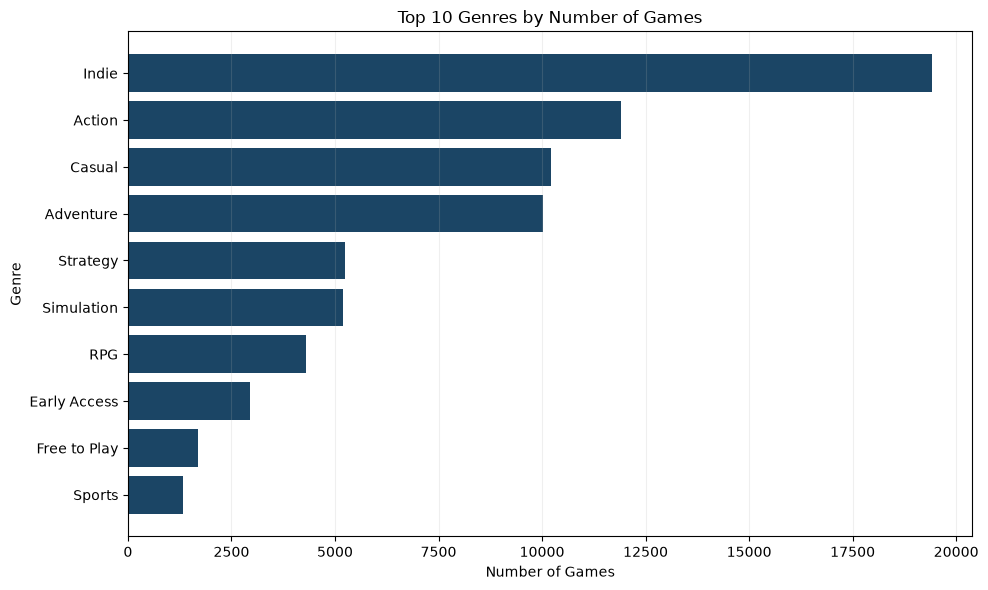

In [34]:
top_genres_by_games = games_count.head(10)
plt.figure(figsize=(10, 6))
plt.barh(top_genres_by_games.index, top_genres_by_games['appid'], color='#1B4565')
plt.gca().invert_yaxis()
plt.title('Top 10 Genres by Number of Games')
plt.xlabel('Number of Games')
plt.ylabel('Genre')
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()

По количеству выпущенных игр лидирует жанр `Indie`, за ним следует `Action`. При этом одна игра может относиться сразу к нескольким жанрам, поэтому количество игр по жанрам не суммируется в общее количество уникальных игр.

#### Количество владельцев по жанрам

Оценим популярность жанров по приблизительному количеству владельцев (`owners_mid`).

Сначала посмотрим на 10 игр с наибольшим количеством владельцев. Затем сгруппируем данные по жанрам и рассчитаем медианное и среднее значения `owners_mid`, чтобы сравнить популярность жанров с учётом влияния самых популярных игр.

Объединим количество игр, среднее и медиану владельцев в таблицу `genre_stats` и построим две горизонтальные столбчатые диаграммы с топ-10 жанров по каждому показателю.

In [35]:
steam_genres.loc[:, ['appid', 'name', 'genres', 'owners', 'owners_min', 'owners_max', 'owners_mid']].sort_values('owners_mid', ascending=False).drop_duplicates('appid').head(10)


,appid,name,genres,owners,owners_min,owners_max,owners_mid
22,570,Dota 2,Action,100000000-200000000,100000000,200000000,150000000.0
12836,578080,PLAYERUNKNOWN'S BATTLEGROUNDS,Massively Multiplayer,50000000-100000000,50000000,100000000,75000000.0
25,730,Counter-Strike: Global Offensive,Free to Play,50000000-100000000,50000000,100000000,75000000.0
1634,230410,Warframe,Free to Play,20000000-50000000,20000000,50000000,35000000.0
3362,304930,Unturned,Free to Play,20000000-50000000,20000000,50000000,35000000.0
19,440,Team Fortress 2,Action,20000000-50000000,20000000,50000000,35000000.0
1025,72850,The Elder Scrolls V: Skyrim,RPG,10000000-20000000,10000000,20000000,15000000.0
7809,433850,Z1 Battle Royale,Free to Play,10000000-20000000,10000000,20000000,15000000.0
1607,227940,Heroes & Generals,Massively Multiplayer,10000000-20000000,10000000,20000000,15000000.0
8129,444090,Paladins®,Free to Play,10000000-20000000,10000000,20000000,15000000.0


In [36]:
median_owners = steam_genres.groupby('genres')['owners_mid'].median().sort_values(ascending=False)
median_owners

genres
Massively Multiplayer    35000.0
Free to Play             35000.0
Web Publishing           22500.0
Animation & Modeling     10000.0
Audio Production         10000.0
Violent                  10000.0
Video Production         10000.0
Utilities                10000.0
Tutorial                 10000.0
Strategy                 10000.0
Sports                   10000.0
Software Training        10000.0
Simulation               10000.0
Sexual Content           10000.0
Racing                   10000.0
RPG                      10000.0
Photo Editing            10000.0
Nudity                   10000.0
Action                   10000.0
Indie                    10000.0
Gore                     10000.0
Game Development         10000.0
Adventure                10000.0
Education                10000.0
Early Access             10000.0
Documentary              10000.0
Design & Illustration    10000.0
Casual                   10000.0
Accounting               10000.0
Name: owners_mid, dtype: float64

In [37]:
mean_owners = steam_genres.groupby('genres')['owners_mid'].mean().sort_values(ascending=False)

In [38]:
genre_stats = pd.concat([games_count, mean_owners, median_owners],axis=1)
genre_stats.columns = ['games_count', 'mean_owners', 'median_owners']
genre_stats

,games_count,mean_owners,median_owners
genres,,,
Indie,19421,75071.314556,10000.0
Action,11903,198411.324876,10000.0
Casual,10210,53558.276200,10000.0
Adventure,10032,109823.066188,10000.0
Strategy,5247,146378.883171,10000.0
Simulation,5194,101261.070466,10000.0
RPG,4311,161648.109487,10000.0
Early Access,2954,52642.180095,10000.0
Free to Play,1704,592667.253521,35000.0


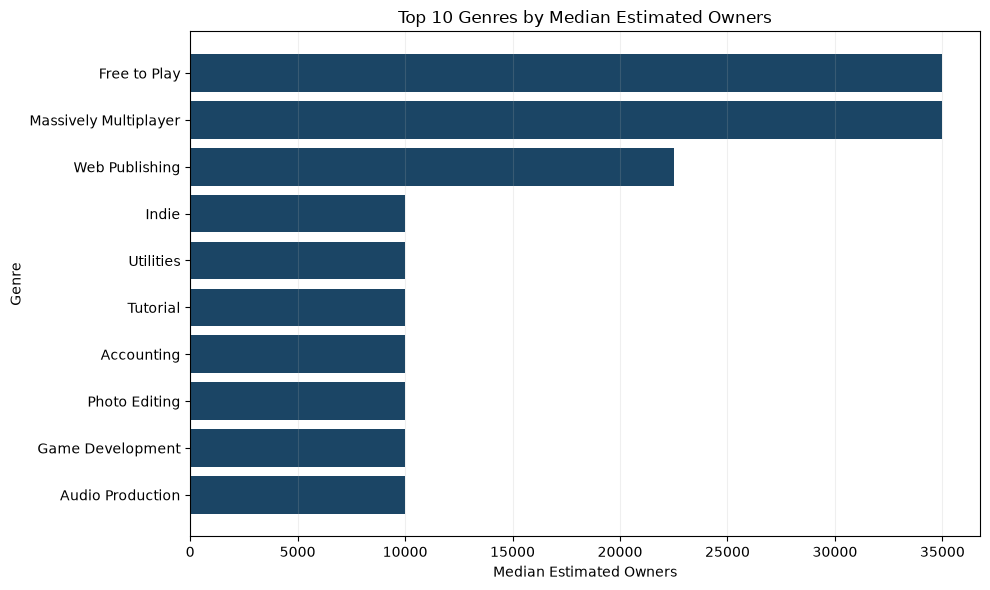

In [39]:
top_genres_by_median_owners = genre_stats.sort_values('median_owners',ascending=False).head(10)
plt.figure(figsize=(10, 6))
plt.barh(top_genres_by_median_owners.index, top_genres_by_median_owners['median_owners'], color="#1B4565")
plt.gca().invert_yaxis()
plt.title('Top 10 Genres by Median Estimated Owners')
plt.xlabel('Median Estimated Owners')
plt.ylabel('Genre')
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()


У большинства жанров медианное количество владельцев одинаковое — 10 000. Поэтому порядок жанров с одинаковой медианой на графике не следует интерпретировать как строгий рейтинг популярности.

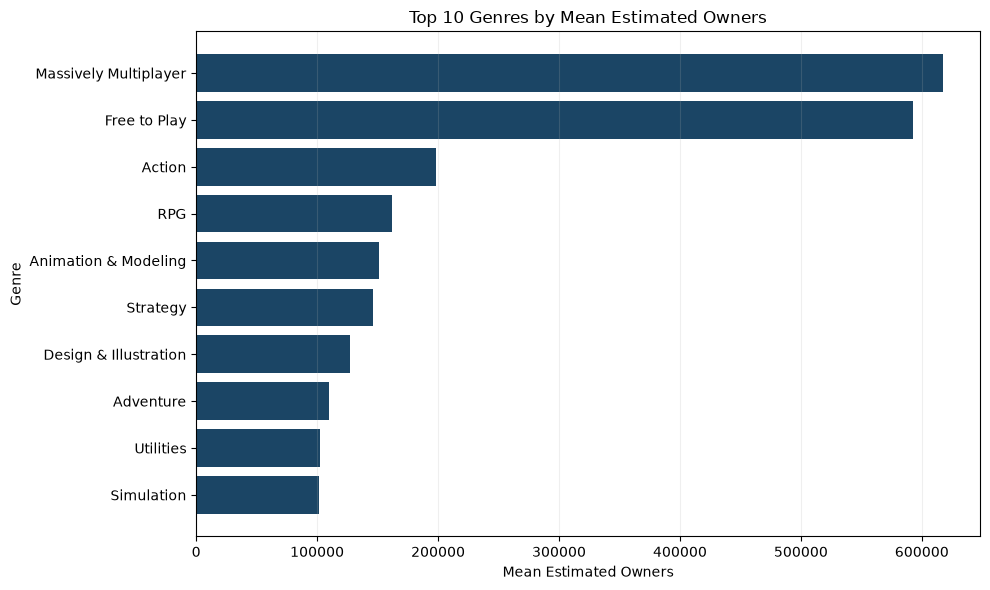

In [40]:
top_genres_by_mean_owners = genre_stats.sort_values('mean_owners',ascending=False).head(10)
plt.figure(figsize=(10, 6))
plt.barh(top_genres_by_mean_owners.index, top_genres_by_mean_owners['mean_owners'], color="#1B4565")
plt.gca().invert_yaxis()
plt.title('Top 10 Genres by Mean Estimated Owners')
plt.xlabel('Mean Estimated Owners')
plt.ylabel('Genre')
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.savefig('images/top_genres_by_owners.png', dpi=300, bbox_inches='tight')

#### Выводы по первому вопросу

По количеству выпущенных игр лидируют `Indie` (19 421 игра, 71,73%) и `Action` (11 903 игры, 43,96%).

Однако для оценки популярности среди пользователей важнее учитывать количество владельцев. По среднему и медианному количеству владельцев лидируют `Massively Multiplayer` и `Free to Play`. При этом медианные значения у многих жанров значительно ниже средних, что указывает на влияние отдельных очень популярных игр.

Также стоит выделить `Action` и `Indie`: оба жанра входят в число лидеров по количеству выпущенных игр и представлены среди ведущих жанров по количеству владельцев. Это говорит не только об их широкой представленности в Steam, но и о популярности среди пользователей.

Таким образом, среди наиболее популярных жанров можно выделить `Massively Multiplayer`, `Free to Play`, а `Action` и `Indie` дополнительно выделяются большим количеством выпущенных игр.

### Связь цены с популярностью и пользовательскими оценками

**Вопрос:** Как цена игры связана с её популярностью и пользовательскими оценками?

Чтобы ответить на этот вопрос разделим игры на ценовые категории и сравним их по приблизительному количеству владельцев и доле положительных отзывов.

#### Анализ распределения цен

Сначала посчитаем количество и долю бесплатных игр в датасете.

Затем рассмотрим описательную статистику цен платных игр с помощью `describe()`. Видим, что средняя цена (£6,71) выше медианной (£4,79), что указывает на смещение распределения в сторону более высоких цен.

Построим гистограмму распределения цен платных игр, чтобы наглядно посмотреть, в каких ценовых диапазонах сосредоточено больше всего игр.

In [41]:
free_games_count = (steam['price'] == 0).sum()
free_games_share = free_games_count/steam['appid'].count()
free_games_count,free_games_share

(np.int64(2560), np.float64(0.09455216989843028))

In [42]:
steam.loc[steam['price'] > 0, 'price'].describe()

count    24515.000000
mean         6.712914
std          8.014336
min          0.320000
25%          2.090000
50%          4.790000
75%          7.490000
max        421.990000
Name: price, dtype: float64

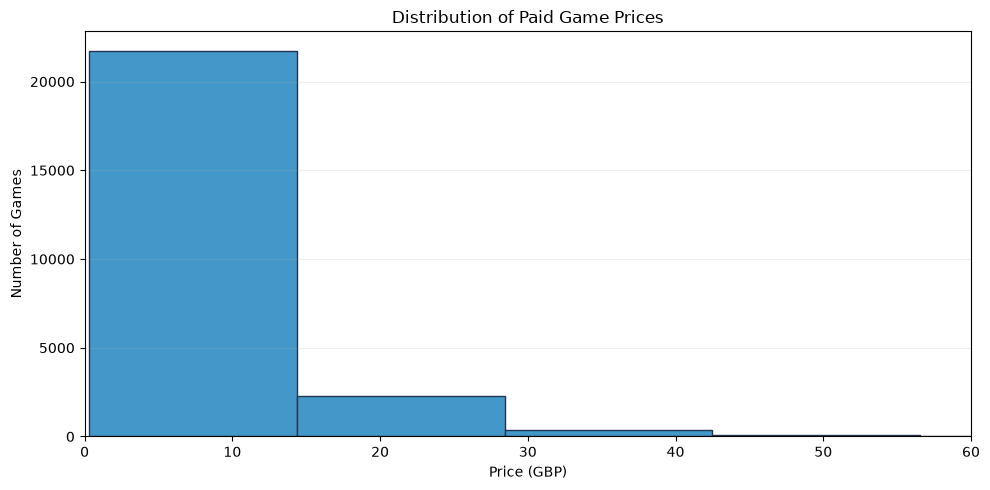

In [43]:
paid_games_prices = steam.loc[steam['price'] > 0, ['price']]
plt.figure(figsize=(10, 5))
plt.hist(paid_games_prices, bins=30, color="#4498C9", edgecolor="#1F3553")
plt.xlim(0, 60)
plt.title('Distribution of Paid Game Prices')
plt.xlabel('Price (GBP)')
plt.ylabel('Number of Games')
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()

Для наглядности на гистограмме показаны цены до £60. Игры с более высокой стоимостью не отображаются на графике.

#### Разделение игр на ценовые категории

По гистограмме видно, что недорогих игр значительно больше, чем дорогих. Поэтому разделим игры на пять ценовых категорий: `Free`, `Budget`, `Low-mid`, `Mid-high` и `Premium`.

Границы категорий определим по квартилям цен платных игр: £2,09 (25%), £4,79 (50%) и £7,49 (75%). Верхней границей последней категории будет максимальная цена в датасете — £421,99. Бесплатные игры выделим в отдельную категорию Free.

Затем посчитаем количество игр в каждой категории и проверим, нет ли пропущенных значений в `price_category`.

In [44]:
max_price = steam['price'].max()
steam['price_category'] = pd.cut(x=steam['price'], bins=[-0.01, 0, 2.09, 4.79, 7.49, max_price], labels=['Free', 'Budget', 'Low-mid', 'Mid-high', 'Premium'])

In [45]:
steam['price_category'].value_counts()

price_category
Budget      6772
Premium     6127
Mid-high    5822
Low-mid     5794
Free        2560
Name: count, dtype: int64

In [46]:
steam['price_category'].isna().sum()

np.int64(0)

#### Связь цены с количеством владельцев

Рассчитаем среднее и медианное количество владельцев (`owners_mid`) для каждой ценовой категории.

Построим столбчатую диаграмму среднего количества владельцев по каждой категории.

In [47]:
mean_owners_by_price_category = steam.groupby('price_category')['owners_mid'].mean()
mean_owners_by_price_category

price_category
Free        442339.843750
Budget       36983.165978
Low-mid      56548.153262
Mid-high     97128.993473
Premium     221076.383222
Name: owners_mid, dtype: float64

In [48]:
steam.groupby('price_category')['owners_mid'].median()

price_category
Free        35000.0
Budget      10000.0
Low-mid     10000.0
Mid-high    10000.0
Premium     10000.0
Name: owners_mid, dtype: float64

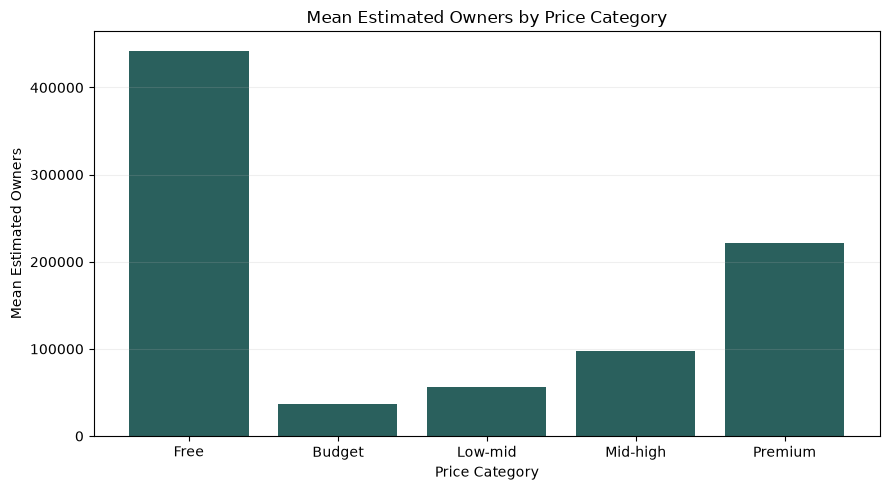

In [49]:
plt.figure(figsize=(9, 5))
plt.bar(mean_owners_by_price_category.index, mean_owners_by_price_category.values, color="#2A605D")
plt.title('Mean Estimated Owners by Price Category')
plt.xlabel('Price Category')
plt.ylabel('Mean Estimated Owners')
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.savefig('images/owners_by_price.png', dpi=300, bbox_inches='tight')

По среднему количеству владельцев заметно лидируют бесплатные игры. При этом высокая средняя популярность может быть связана с отдельными очень популярными играми.

#### Связь цены с пользовательскими оценками

Рассчитаем среднюю и медианную долю положительных отзывов (`positive_ratio`) для каждой ценовой категории.

Построим столбчатую диаграмму средней доли положительных отзывов по каждой категории.

In [50]:
mean_positive_ratio_by_price_category = steam.groupby('price_category')['positive_ratio'].mean()

In [51]:
steam.groupby('price_category')['positive_ratio'].median()

price_category
Free        0.735150
Budget      0.708333
Low-mid     0.750000
Mid-high    0.793103
Premium     0.800000
Name: positive_ratio, dtype: float64

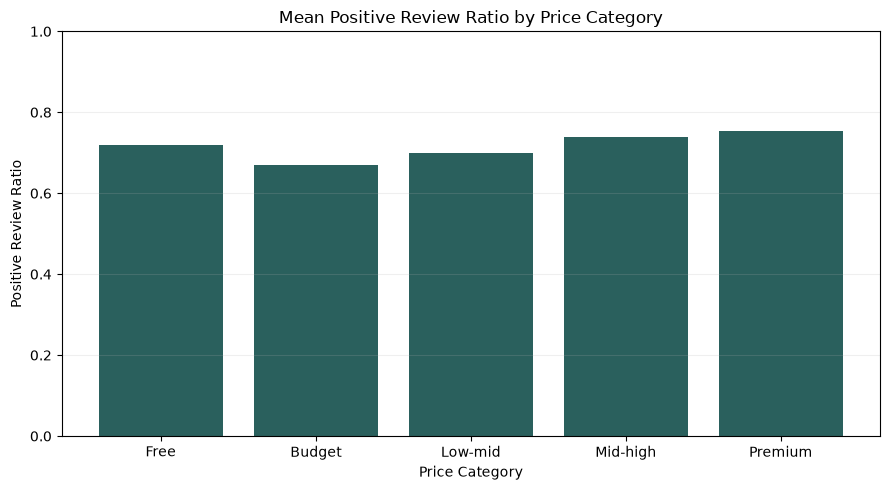

In [52]:
plt.figure(figsize=(9, 5))
plt.bar(mean_positive_ratio_by_price_category.index, mean_positive_ratio_by_price_category.values, color="#2A605D")
plt.title('Mean Positive Review Ratio by Price Category')
plt.xlabel('Price Category')
plt.ylabel('Positive Review Ratio')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()

Средняя доля положительных отзывов во всех ценовых категориях находится примерно на одном уровне. Значительных различий между категориями не наблюдается.

#### Выводы по второму вопросу

По среднему количеству владельцев заметно лидируют бесплатные игры, на втором месте находятся игры категории `Premium`. При этом бюджетные платные игры имеют наименьшее среднее количество владельцев. Медианные значения у платных категорий примерно одинаковые, несмотря на заметные различия в средних, что указывает на влияние отдельных очень популярных игр.

По пользовательским оценкам лидируют игры категории `Premium`, хотя различия в средней доле положительных отзывов между ценовыми категориями относительно небольшие.

Таким образом, в исследуемых данных не наблюдается однозначной закономерности, при которой более низкая цена соответствует большей популярности или более высокой доле положительных отзывов. Бесплатные игры лидируют по среднему количеству владельцев, тогда как премиальные игры также демонстрируют высокую популярность и лучшие средние пользовательские оценки.

### Игры с наиболее положительными оценками

**Вопрос:** Какие игры получают наиболее положительные оценки пользователей?

Рассмотрим игры с самой высокой долей положительных отзывов (`positive_ratio`) и проверим, как количество отзывов влияет на интерпретацию этого показателя.

#### Игры со 100% положительных отзывов

Посчитаем количество игр, у которых `positive_ratio` равен 1, то есть все отзывы положительные.

Затем рассмотрим описательную статистику `total_ratings`, чтобы оценить количество отзывов у таких игр. Проверим, сколько из них имеют менее 10 отзывов, поскольку 100% положительных оценок при небольшом количестве отзывов не всегда является надёжным показателем высокой оценки игры.

In [53]:
(steam['positive_ratio'] == 1).sum()

np.int64(2906)

In [54]:
steam.loc[steam['positive_ratio'] == 1, ['total_ratings']].describe()

,total_ratings
count,2906.000000
mean,6.751893
std,9.339976
min,1.000000
25%,2.000000
50%,4.000000
75%,8.000000
max,114.000000


In [55]:
((steam['positive_ratio'] == 1) & (steam['total_ratings'] < 10)).sum()

np.int64(2307)

#### Игры с большим количеством отзывов

Чтобы не ориентироваться только на игры с небольшим количеством отзывов, рассмотрим топ-10 игр по доле положительных отзывов среди тех, у которых не менее 100 отзывов.

Затем повысим порог до 1000 отзывов и сравним результаты.

In [56]:
steam.loc[steam['total_ratings'] >= 100, ['appid', 'name', 'total_ratings', 'positive_ratio']].sort_values('positive_ratio', ascending=False).head(10)

,appid,name,total_ratings,positive_ratio
25913,992740,祈風 Inorikaze,114,1.000000
8548,454380,Champions of Breakfast,112,1.000000
23296,888790,Sabbat of the Witch,523,0.996176
13937,611760,Don't Escape: 4 Days in a Wasteland,193,0.994819
22281,858940,Flowers -Le volume sur ete-,183,0.994536
23545,896460,Lucah: Born of a Dream,160,0.993750
24596,937580,東方紺珠伝 ～ Legacy of Lunatic Kingdom.,152,0.993421
26780,1037190,Shipped,298,0.993289
23080,882110,Google Spotlight Stories: Age of Sail,149,0.993289
23867,910630,Arcade Spirits,138,0.992754


In [57]:
steam.loc[steam['total_ratings'] >= 1000, ['appid', 'name', 'total_ratings', 'positive_ratio']].sort_values('positive_ratio', ascending=False).head(10)

,appid,name,total_ratings,positive_ratio
18404,745880,東方天空璋 ～ Hidden Star in Four Seasons.,4167,0.987281
23,620,Portal 2,140111,0.986504
7577,427520,Factorio,48641,0.985136
7130,411960,TY the Tasmanian Tiger,1702,0.984724
7755,432350,Epic Battle Fantasy 5,1092,0.982601
2290,264200,One Finger Death Punch,14437,0.982268
4344,337340,Finding Paradise,6701,0.981645
23649,899970,NEKOPARA Extra,1556,0.981362
7509,424280,Iron Snout,14166,0.980446
18113,736260,Baba Is You,1326,0.980392


#### Выводы по третьему вопросу

В датасете обнаружено 2 906 игр со 100% положительных отзывов. Однако 2 307 из них имеют менее 10 отзывов, поэтому идеальная доля положительных оценок не всегда является достаточно убедительным показателем.

Для более надёжного сравнения мы рассмотрели игры с минимум 100 и 1000 отзывов. Среди игр с не менее чем 1000 отзывов можно выделить `Hidden Star in Four Seasons` (98,73% положительных отзывов, 4 167 отзывов) и `Portal 2` (98,65%, 140 111 отзывов).

Таким образом, эти игры входят в число наиболее высоко оценённых пользователями в рассматриваемом датасете. При этом важно учитывать не только долю положительных отзывов, но и их общее количество.

### Динамика выпуска игр

**Вопрос:** Как изменялось количество выпускаемых игр в Steam с течением времени?

Рассмотрим количество выпущенных игр по годам и оценим, как менялись темпы их выпуска.

#### Количество выпущенных игр по годам

Сгруппируем данные по `release_year` и посчитаем количество выпущенных игр в каждом году.

Построим линейный график, чтобы посмотреть, как изменялось количество релизов с течением времени.

In [58]:
games_per_year = steam.groupby('release_year')['appid'].count()
games_per_year

release_year
1997       1
1998       1
1999       2
2000       2
2001       4
2002       1
2003       3
2004       6
2005       6
2006      48
2007      93
2008     145
2009     305
2010     238
2011     239
2012     320
2013     418
2014    1555
2015    2597
2016    4361
2017    6357
2018    8160
2019    2213
Name: appid, dtype: int64

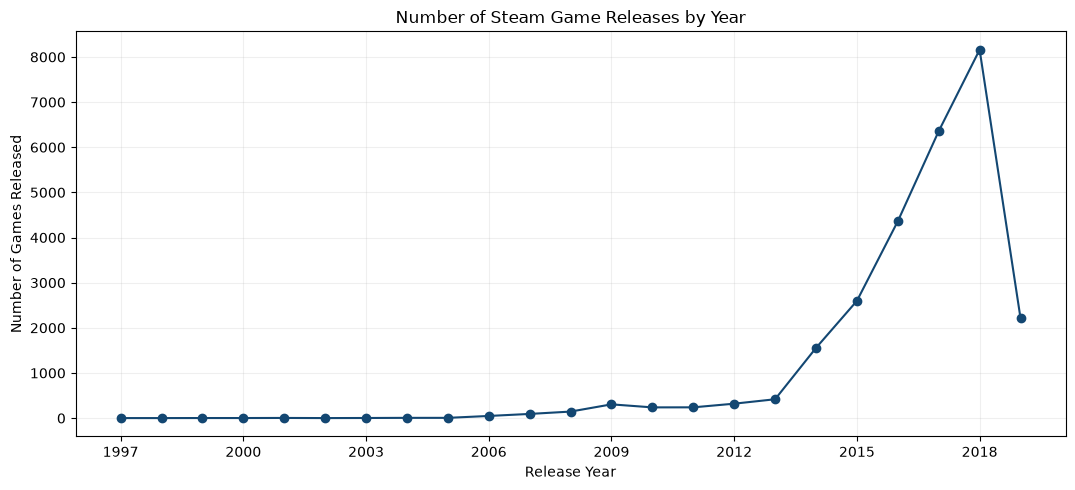

In [59]:
plt.figure(figsize=(11, 5))
plt.plot(games_per_year.index,games_per_year.values, color = "#134772", marker='o')
plt.title('Number of Steam Game Releases by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Games Released')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.xticks(games_per_year.index[::3])
plt.savefig('images/games_per_year.png', dpi=300, bbox_inches='tight')

По графику видно, что с 2014 года количество выпускаемых игр начало резко расти, а пик пришёлся на 2018 год.

#### Темпы роста количества игр

Рассчитаем ежегодное процентное изменение количества выпущенных игр с помощью `pct_change()` и отсортируем результаты, чтобы определить годы с наибольшими темпами роста.

Исключим 2019 год из сравнения, поскольку данные за него неполные и могут искажать результаты.

In [60]:
games_per_year.loc[:2018].pct_change(periods=1).sort_values(ascending=False)*100

release_year
2006    700.000000
2014    272.009569
2003    200.000000
2009    110.344828
2001    100.000000
2004    100.000000
1999    100.000000
2007     93.750000
2016     67.924528
2015     67.009646
2008     55.913978
2017     45.769319
2012     33.891213
2013     30.625000
2018     28.362435
2011      0.420168
2005      0.000000
2000      0.000000
1998      0.000000
2010    -21.967213
2002    -75.000000
1997           NaN
Name: appid, dtype: float64

#### Выводы по четвёртому вопросу

До 2014 года количество выпускаемых игр оставалось относительно небольшим и росло медленно. Начиная с 2014 года наблюдается резкий рост числа релизов, достигший пика в 2018 году.

При этом наибольший относительный прирост наблюдался в 2006 году и составил 700% по сравнению с предыдущим годом. Однако такой высокий процент может быть связан с небольшим количеством выпущенных игр в предыдущем году.

Данные за 2019 год неполные, поэтому этот год не учитывался при сравнении темпов роста.

Таким образом, количество выпускаемых игр в Steam заметно увеличивалось с течением времени, особенно в период с 2014 по 2018 год.

### Характеристики наиболее популярных игр

**Вопрос:** Какие характеристики отличают самые популярные игры?

Выделим наиболее популярные игры по приблизительному количеству владельцев (`owners_mid`) и сравним их с остальными по цене, пользовательским оценкам и жанрам.

#### Выделение наиболее популярных игр

Найдём 90-й процентиль `owners_mid`, чтобы определить порог для выделения примерно 10% игр с наибольшим количеством владельцев.

Полученный порог составляет 150 000 владельцев. Затем посчитаем количество игр, у которых `owners_mid` превышает это значение.

In [61]:
steam['owners_mid'].quantile(0.9)

np.float64(150000.0)

In [62]:
steam[steam['owners_mid'] > 150000.0]['appid'].count()

np.int64(2339)

#### Сравнение игр по цене

Рассчитаем среднее и медианное значения `price` для популярных игр (`owners_mid > 150000`).

Затем рассчитаем те же показатели для остальных игр (`owners_mid <= 150000`), чтобы сравнить цены между двумя группами.

In [63]:
steam[steam['owners_mid'] > 150000.0]['price'].median()

np.float64(6.99)

In [64]:
steam[steam['owners_mid'] > 150000.0]['price'].mean()

np.float64(8.805446772124837)

In [65]:
steam[steam['owners_mid'] <= 150000.0]['price'].median()

np.float64(3.99)

In [66]:
steam[steam['owners_mid'] <= 150000.0]['price'].mean()

np.float64(5.820308053040104)

#### Сравнение игр по пользовательским оценкам

Рассчитаем среднюю и медианную долю положительных отзывов (`positive_ratio`) для популярных игр (`owners_mid > 150000`).

Затем рассчитаем те же показатели для остальных игр (`owners_mid <= 150000`), чтобы сравнить пользовательские оценки между двумя группами.

In [67]:
steam[steam['owners_mid'] > 150000.0]['positive_ratio'].median()

np.float64(0.8116760828625236)

In [68]:
steam[steam['owners_mid'] > 150000.0]['positive_ratio'].mean()

np.float64(0.7695252657555588)

In [69]:
steam[steam['owners_mid'] <= 150000.0]['positive_ratio'].median()

np.float64(0.75)

In [70]:
steam[steam['owners_mid'] <= 150000.0]['positive_ratio'].mean()

np.float64(0.7092727270111597)

#### Популярность игр по жанрам

Выделим игры с `owners_mid > 150000`, сгруппируем их по жанрам и посчитаем количество уникальных популярных игр в каждом жанре.

Затем рассчитаем общее количество игр по каждому жанру и определим, какой процент среди них составляют популярные игры.

In [71]:
popular_games_by_genre = steam_genres[steam_genres['owners_mid'] > 150000.0].groupby('genres')['appid'].nunique().sort_values(ascending=False)
popular_games_by_genre

genres
Action                   1261
Indie                    1214
Adventure                 780
Strategy                  543
RPG                       519
Casual                    441
Free to Play              408
Simulation                395
Massively Multiplayer     190
Early Access              120
Sports                     79
Racing                     74
Violent                    40
Gore                       26
Nudity                     22
Sexual Content             16
Utilities                   7
Design & Illustration       4
Animation & Modeling        4
Video Production            2
Web Publishing              2
Game Development            1
Software Training           1
Education                   1
Name: appid, dtype: int64

In [72]:
total_games_by_genre = steam_genres.groupby('genres')['appid'].nunique()
total_games_by_genre

genres
Accounting                   6
Action                   11903
Adventure                10032
Animation & Modeling        79
Audio Production            29
Casual                   10210
Design & Illustration       87
Documentary                  1
Early Access              2954
Education                   51
Free to Play              1704
Game Development            17
Gore                       537
Indie                    19421
Massively Multiplayer      723
Nudity                     266
Photo Editing               12
RPG                       4311
Racing                    1024
Sexual Content             245
Simulation                5194
Software Training           31
Sports                    1322
Strategy                  5247
Tutorial                     1
Utilities                  146
Video Production            38
Violent                    843
Web Publishing              28
Name: appid, dtype: int64

In [73]:
((popular_games_by_genre/total_games_by_genre)*100).fillna(0).sort_values(ascending=False)

genres
Massively Multiplayer    26.279391
Free to Play             23.943662
RPG                      12.038970
Action                   10.593968
Strategy                 10.348771
Nudity                    8.270677
Adventure                 7.775120
Simulation                7.604929
Racing                    7.226562
Web Publishing            7.142857
Sexual Content            6.530612
Indie                     6.250965
Sports                    5.975794
Game Development          5.882353
Video Production          5.263158
Animation & Modeling      5.063291
Gore                      4.841713
Utilities                 4.794521
Violent                   4.744958
Design & Illustration     4.597701
Casual                    4.319295
Early Access              4.062288
Software Training         3.225806
Education                 1.960784
Tutorial                  0.000000
Audio Production          0.000000
Photo Editing             0.000000
Documentary               0.000000
Accounting   

#### Выводы по пятому вопросу

Для анализа наиболее популярных игр мы выделили игры с приблизительным количеством владельцев более 150 000.

Сравнение показало, что популярные игры в среднем дороже остальных (£8,81 против £5,82). Медианная цена также выше — £6,99 против £3,99.

По пользовательским оценкам популярные игры тоже имеют более высокие показатели: средняя доля положительных отзывов составляет 76,95% против 70,93%, а медианная — 81,17% против 75%.

По жанрам наибольшая доля популярных игр наблюдается у `Massively Multiplayer`, `Free to Play`, `RPG` и `Action`.

Таким образом, наиболее популярные игры в рассматриваемом датасете отличаются более высокой средней и медианной ценой, более высокой долей положительных отзывов и чаще встречаются среди популярных игр в перечисленных жанрах. При этом выявленные различия не доказывают, что именно цена, отзывы или жанр определяют популярность игры.

## 4. Conclusions and Recommendations


### Общие выводы

В ходе анализа мы рассмотрели 27 075 игр Steam и исследовали их жанры, цены, количество владельцев, пользовательские оценки и динамику выпуска.

Среди наиболее популярных жанров выделяются `Massively Multiplayer` и `Free to Play`, которые лидируют по среднему и медианному количеству владельцев. Также стоит отметить `Action`: он входит в топ-10 по среднему количеству владельцев и имеет относительно высокую долю популярных игр внутри жанра.

Анализ цен показал, что бесплатные игры лидируют по среднему количеству владельцев, а игры категории `Premium` занимают второе место. При этом средняя доля положительных отзывов во всех ценовых категориях находится примерно на одном уровне, хотя у `Premium` она немного выше.

Сравнение наиболее популярных игр с остальными показало, что популярные игры в среднем дороже и имеют более высокую долю положительных отзывов.

Также мы обнаружили, что количество выпускаемых игр значительно выросло начиная с 2014 года и достигло максимума в 2018 году.

Стоит учитывать, что в исходных данных количество владельцев представлено диапазонами. Для анализа мы использовали `owners_mid` — середину каждого диапазона, поэтому полученные значения являются приблизительными и не отражают точное количество владельцев.

### Рекомендации

По результатам анализа Steam стоит обратить внимание на ценовые категории `Free` и `Premium`. Бесплатные игры лидируют по среднему количеству владельцев, а премиальные игры также показывают высокую популярность и имеют наибольшую среднюю долю положительных отзывов.

Среди жанров стоит выделить `Massively Multiplayer`, `Free to Play` и `Action`. Первые два лидируют по количеству владельцев и доле популярных игр внутри жанра. `Action` также входит в топ-10 по среднему количеству владельцев и по количеству выпущенных игр, что дополнительно подтверждает его популярность.

При этом результаты исследования не означают, что популярность игры напрямую зависит от её цены или жанра. Эти характеристики могут быть связаны с популярностью, но сами по себе не гарантируют её.